## Project 3: learned data fusion

### Cloning the repo from GitHub

In [1]:
import os
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

%cd /content
if not os.path.exists('/content/3D_Perception'):
    !git clone https://github.com/giacomosalvatori03/3D_Perception.git
%cd /content/3D_Perception
!git pull
!git fetch origin
!git checkout project3-fusion
!git pull origin project3-fusion

Mounted at /content/drive
/content
Cloning into '3D_Perception'...
remote: Enumerating objects: 818, done.
remote: Counting objects: 100% (101/101), done.
remote: Compressing objects: 100% (70/70), done.
remote: Total 818 (delta 68), reused 63 (delta 31), pack-reused 717 (from 2)
Receiving objects: 100% (818/818), 56.40 MiB | 20.30 MiB/s, done.
Resolving deltas: 100% (516/516), done.
/content/3D_Perception
Already up to date.
branch 'project3-fusion' set up to track 'origin/project3-fusion'.
Switched to a new branch 'project3-fusion'
From https://github.com/giacomosalvatori03/3D_Perception
 * branch            project3-fusion -> FETCH_HEAD
Already up to date.


#### Folder paths and device setup

In [2]:
import torch

# Paths in Google Drive
PRED_3D_BASELINE = "/content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc/pred_labels"
PRED_2D_YOLO = "/content/drive/MyDrive/3D_Perception/experiments_camera/yolov8m_baseline_2d/pred_labels"
GT_3D_DIR = "/content/drive/MyDrive/3D_Perception/experiments_camera/baseline_100perc/gt_labels"
CHECKPOINT_DIR = "/content/drive/MyDrive/3D_Perception/data/models_checkpoints"
CALIB_DIR = "/content/drive/MyDrive/3D_Perception/data/kitti_validation/calib"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Training phase on baseline for CLOCs model

In [3]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from src.fast_cloc_trainer import FastCLOCsTrainer

print("--- Starting Fast-CLOCs Training ---")
trainer = FastCLOCsTrainer(
    pred_3d_dir=PRED_3D_BASELINE,
    pred_2d_dir=PRED_2D_YOLO,
    gt_3d_dir=GT_3D_DIR,
    calib_dir=CALIB_DIR,                  # Fondamentale per la proiezione 2D-3D corretta
    output_checkpoint_dir=CHECKPOINT_DIR,
    batch_size=128,
    epochs=35,
    lr=0.001,
    pos_weight_val=1.5,                   # Bilanciamento per desaturare gli score di confidenza
    val_split=0.2,                        # 80% Train (~400 frame), 20% Val (~100 frame)
    seed=42,
    device=str(device)
)

trainer.fit()

--- Starting Fast-CLOCs Training ---
Device selected: cpu
Frame-Level Split -> Total Frames: 500 | Train Frames: 400 | Val Frames: 100
Validation frame list exported to: /content/drive/MyDrive/3D_Perception/data/models_checkpoints/val_frames.txt
Extracting training candidate pairs...
Extracting validation candidate pairs...
Candidate pairs extracted -> Train pairs: 3798 | Val pairs: 983

--- Starting Fast-CLOCs Training Loop ---
Epoch 01/35 | Train Loss: 0.5742 | Val Loss: 0.5402 | Acc: 78.5% | Prec: 66.9% | Rec: 94.8% | F1: 78.4% [BEST SAVED]
Epoch 04/35 | Train Loss: 0.4533 | Val Loss: 0.3776 | Acc: 87.4% | Prec: 81.6% | Rec: 89.6% | F1: 85.4% [BEST SAVED]
Epoch 05/35 | Train Loss: 0.3915 | Val Loss: 0.3547 | Acc: 87.1% | Prec: 80.2% | Rec: 91.1% | F1: 85.3% 
Epoch 06/35 | Train Loss: 0.3629 | Val Loss: 0.3444 | Acc: 87.9% | Prec: 81.5% | Rec: 91.4% | F1: 86.1% [BEST SAVED]
Epoch 07/35 | Train Loss: 0.3493 | Val Loss: 0.3244 | Acc: 88.9% | Prec: 84.1% | Rec: 90.1% | F1: 87.0% [BEST S

### Multi-regime inference on 3D candidates

In [5]:
import os
import sys

# 1. Assicura l'installazione di shapely per il calcolo dell'IoU 3D BEV
!pip install -q shapely

# 2. Inserimento percorso repository nel PYTHONPATH
sys.path.insert(0, "/content/3D_Perception")

from validate_learn_fusion import FastCLOCsEvaluator

# 3. Definizioni percorsi modello e file di validazione
MODEL_PATH = os.path.join(CHECKPOINT_DIR, "fast_cloc_best.pth")
VAL_FRAMES_FILE = os.path.join(CHECKPOINT_DIR, "val_frames.txt")
FASTCLOC_OUTPUT_BASE = "/content/drive/MyDrive/3D_Perception/experiments_fastcloc"

# Percorso base delle predizioni 3D nei vari regimi di degradazione
BASE_DIR = "/content/drive/MyDrive/3D_Perception/experiments_camera"

# Mappa dei regimi sperimentali
regimes = {
    "baseline_100perc": os.path.join(BASE_DIR, "baseline_100perc", "pred_labels"),
    "random_75perc":    os.path.join(BASE_DIR, "random_75perc", "pred_labels"),
    "random_50perc":    os.path.join(BASE_DIR, "random_50perc", "pred_labels"),
    "random_25perc":    os.path.join(BASE_DIR, "random_25perc", "pred_labels"),
    "beam_32rings":     os.path.join(BASE_DIR, "beam_32rings", "pred_labels"),
    "beam_16rings":     os.path.join(BASE_DIR, "beam_16rings", "pred_labels") 
}

# 4. Inizializzazione del motore di inferenza
evaluator = FastCLOCsEvaluator(model_path=MODEL_PATH, device=str(device))

# 5. Esecuzione dell'inferenza Fast-CLOCs per ciascun regime
print("--- Starting Fast-CLOCs Learned Fusion Inference ---")
for regime_name, pred_3d_dir in regimes.items():
    output_dir = os.path.join(FASTCLOC_OUTPUT_BASE, regime_name)
    print(f"\nProcessing Fast-CLOCs Inference: [{regime_name}]")
    
    evaluator.run_inference(
        pred_3d_dir=pred_3d_dir,
        pred_2d_dir=PRED_2D_YOLO,
        output_dir=output_dir,
        gt_3d_dir=GT_3D_DIR,
        calib_dir=CALIB_DIR,
        val_frames_file=VAL_FRAMES_FILE,
        conf_thresh=0.25,     # Utilizzare 0.25 per la Confusion Matrix, 0.01 per la mAP40 ufficiale
        nms_thresh=0.20       # NMS 3D BEV per la soppressione dei duplicati vicini
    )

FastCLOCsEvaluator initialized with weights from: /content/drive/MyDrive/3D_Perception/data/models_checkpoints/fast_cloc_best.pth
--- Starting Fast-CLOCs Learned Fusion Inference ---

Processing Fast-CLOCs Inference: [baseline_100perc]
Filtering evaluation to 100 validation frames specified in: /content/drive/MyDrive/3D_Perception/data/models_checkpoints/val_frames.txt
Inference complete. Processed 100 frames | Copied 100 GT files -> Output saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/baseline_100perc

Processing Fast-CLOCs Inference: [random_75perc]
Filtering evaluation to 100 validation frames specified in: /content/drive/MyDrive/3D_Perception/data/models_checkpoints/val_frames.txt
Inference complete. Processed 100 frames | Copied 100 GT files -> Output saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/random_75perc

Processing Fast-CLOCs Inference: [random_50perc]
Filtering evaluation to 100 validation frames specified in: /content/drive/MyDr

### Fusion evaluation

In [6]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from IPython.display import display
from scripts.lidar_evaluator import KittiEvaluator

experiments = [
    "baseline_100perc",
    "random_75perc",
    "random_50perc",
    "random_25perc",
    "beam_32rings",
    "beam_16rings",
]

evaluator_3d = KittiEvaluator()

# Evaluation cycle
for exp_name in experiments:
    exp_dir = os.path.join(FASTCLOC_OUTPUT_BASE, exp_name)

    print(f"\n" + "=" * 50)
    print(f"  Validating: {exp_name}")
    print("=" * 50)

    evaluator_3d.evaluate(exp_dir=exp_dir)
    evaluator_3d.evaluate_ranges(exp_dir=exp_dir)


  Validating: baseline_100perc

 OVERALL 3D DETECTION mAP40 [baseline_100perc]



,Easy,Moderate,Hard
Class,,,
Car,73.03%,66.43%,63.82%
Pedestrian,67.90%,63.97%,63.55%
Cyclist,48.57%,45.00%,48.99%



 Reports saved in '/content/drive/MyDrive/3D_Perception/experiments_fastcloc/baseline_100perc': .json, .csv, .md, .tex

 RANGE-BASED mAP40 RESULTS [baseline_100perc]



Class,Car,Cyclist,Pedestrian
Range,,,
Far (40-70m),26.57%,0.00%,0.00%
Medium (20-40m),59.41%,25.00%,55.67%
Near (0-20m),84.10%,60.00%,68.74%



 Range reports saved in '/content/drive/MyDrive/3D_Perception/experiments_fastcloc/baseline_100perc': .csv, .json

  Validating: random_75perc

 OVERALL 3D DETECTION mAP40 [random_75perc]



,Easy,Moderate,Hard
Class,,,
Car,67.07%,62.76%,58.57%
Pedestrian,66.47%,63.61%,62.07%
Cyclist,48.57%,45.00%,51.14%


... (15 outputs left out)

,Easy,Moderate,Hard
Class,,,
Car,59.55%,40.13%,35.86%
Pedestrian,35.57%,29.84%,29.51%
Cyclist,10.00%,13.33%,26.00%



 Reports saved in '/content/drive/MyDrive/3D_Perception/experiments_fastcloc/beam_16rings': .json, .csv, .md, .tex

 RANGE-BASED mAP40 RESULTS [beam_16rings]



Class,Car,Cyclist,Pedestrian
Range,,,
Far (40-70m),5.00%,0.00%,0.00%
Medium (20-40m),22.05%,0.00%,0.00%
Near (0-20m),72.19%,26.67%,42.11%



 Range reports saved in '/content/drive/MyDrive/3D_Perception/experiments_fastcloc/beam_16rings': .csv, .json


In [3]:
pred_sample = "/content/drive/MyDrive/3D_Perception/experiments_fastcloc/baseline_100perc/pred_labels/000047.txt"
gt_sample = "/content/drive/MyDrive/3D_Perception/data/kitti_validation/label_2/000047.txt"

print("--- GT SAMPLE ---")
with open(gt_sample, 'r') as f:
    for line in f:
        if line.startswith("Car"):
            parts = line.strip().split()
            print(f"Cls: {parts[0]} | 2D: {parts[4:8]} | Dim(h,w,l): {parts[8:11]} | Loc(x,y,z): {parts[11:14]} | Ry: {parts[14]}")

print("\n--- PRED SAMPLE ---")
with open(pred_sample, 'r') as f:
    for line in f:
        if line.startswith("Car"):
            parts = line.strip().split()
            print(f"Cls: {parts[0]} | 2D: {parts[4:8]} | Dim(h,w,l): {parts[8:11]} | Loc(x,y,z): {parts[11:14]} | Ry: {parts[14]} | Score: {parts[15]}")

--- GT SAMPLE ---
Cls: Car | 2D: ['572.31', '171.60', '624.11', '218.82'] | Dim(h,w,l): ['1.60', '1.76', '3.84'] | Loc(x,y,z): ['-0.38', '1.13', '26.54'] | Ry: -1.58
Cls: Car | 2D: ['0.00', '190.67', '171.41', '313.27'] | Dim(h,w,l): ['1.47', '1.54', '3.51'] | Loc(x,y,z): ['-8.37', '1.59', '10.68'] | Ry: -1.57
Cls: Car | 2D: ['214.99', '165.20', '423.55', '292.98'] | Dim(h,w,l): ['1.78', '1.81', '4.32'] | Loc(x,y,z): ['-4.65', '1.49', '12.25'] | Ry: -1.57
Cls: Car | 2D: ['296.94', '182.19', '393.12', '231.61'] | Dim(h,w,l): ['1.45', '1.61', '4.30'] | Loc(x,y,z): ['-8.54', '1.37', '23.68'] | Ry: -1.58
Cls: Car | 2D: ['428.19', '180.81', '498.01', '226.24'] | Dim(h,w,l): ['1.45', '1.67', '3.88'] | Loc(x,y,z): ['-5.00', '1.30', '25.13'] | Ry: -1.58
Cls: Car | 2D: ['522.27', '176.55', '552.71', '202.38'] | Dim(h,w,l): ['1.63', '1.67', '3.92'] | Loc(x,y,z): ['-4.64', '1.07', '47.70'] | Ry: -1.58
Cls: Car | 2D: ['0.00', '185.88', '180.39', '253.13'] | Dim(h,w,l): ['1.42', '1.57', '4.23'] | L

In [8]:
import sys

sys.path.insert(0, "/content/3D_Perception")

from IPython.display import display
from scripts.experiment_comparer import ExperimentComparer

learned_fusion_root = (
    "/content/drive/MyDrive/3D_Perception/experiments_fastcloc"
)

# Initialize the comparer by specifying the reference folders
comparer = ExperimentComparer(
    experiments_root="/content/drive/MyDrive/3D_Perception/experiments",
    fusion_root=learned_fusion_root,
)

### Car - Easy difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_easy.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_easy.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,67.40%,73.03%,+5.63%,+8.36%
1,random_75perc,65.34%,67.07%,+1.73%,+2.64%
2,random_50perc,65.17%,68.22%,+3.05%,+4.68%
3,beam_32rings,68.04%,76.96%,+8.92%,+13.10%
4,random_25perc,55.26%,58.06%,+2.80%,+5.07%
5,beam_16rings,49.00%,59.55%,+10.55%,+21.53%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_car_easy.png


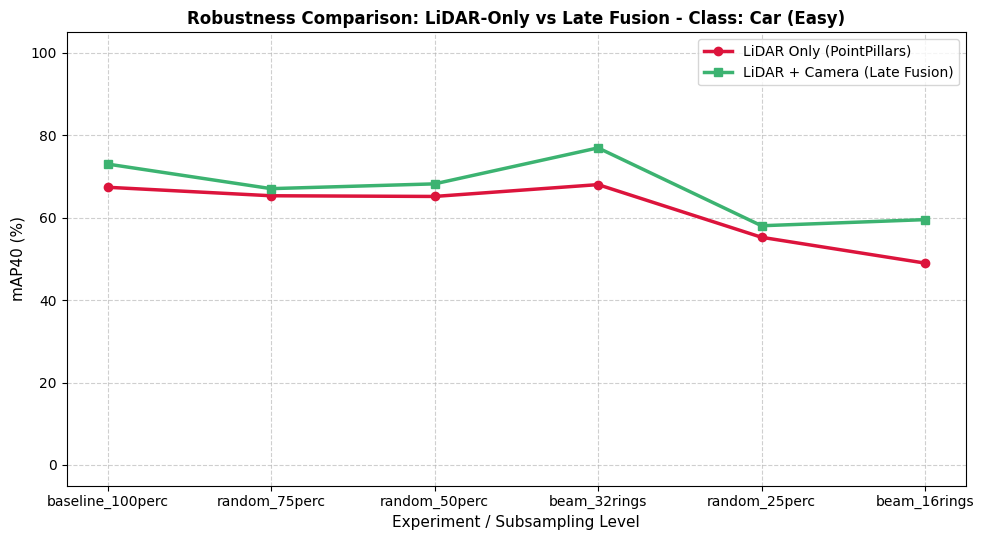

In [9]:
# Compute the gain matrix for the "Car" class under "Easy" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Car",
    difficulty="Easy",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Car" class under "Easy" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Car",
    difficulty="Easy",
    exclude_64beams=True,   # Remove 64 beams
    save_path=f"{learned_fusion_root}/overlay_car_easy.png",
)

### Car - Moderate difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_moderate.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_moderate.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,62.71%,66.43%,+3.71%,+5.92%
1,random_75perc,59.62%,62.76%,+3.14%,+5.26%
2,random_50perc,54.77%,58.24%,+3.47%,+6.34%
3,beam_32rings,56.61%,60.34%,+3.73%,+6.59%
4,random_25perc,43.81%,46.42%,+2.61%,+5.95%
5,beam_16rings,36.80%,40.13%,+3.33%,+9.05%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_car_moderate.png


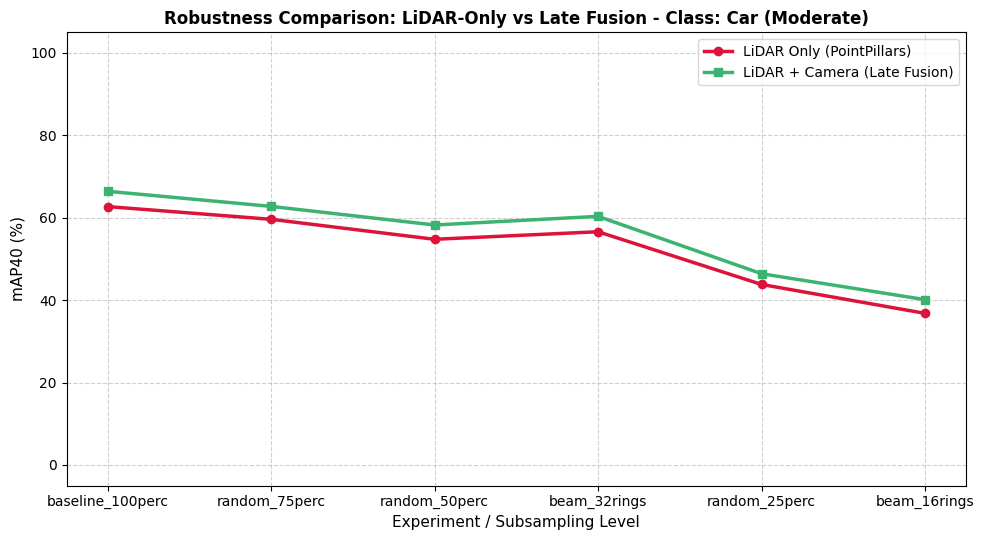

In [10]:
# Compute the gain matrix for the "Car" class under "Moderate" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Car",
    difficulty="Moderate",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Car" class under "Moderate" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Car",
    difficulty="Moderate",
    exclude_64beams=True,   # Remove 64 beams
    save_path=f"{learned_fusion_root}/overlay_car_moderate.png",
)

### Car - Hard difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_hard.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_car_hard.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,59.77%,63.82%,+4.05%,+6.78%
1,random_75perc,56.88%,58.57%,+1.70%,+2.98%
2,random_50perc,51.99%,54.11%,+2.12%,+4.09%
3,beam_32rings,52.01%,53.76%,+1.75%,+3.36%
4,random_25perc,39.42%,40.62%,+1.21%,+3.06%
5,beam_16rings,33.85%,35.86%,+2.01%,+5.95%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_car_hard.png


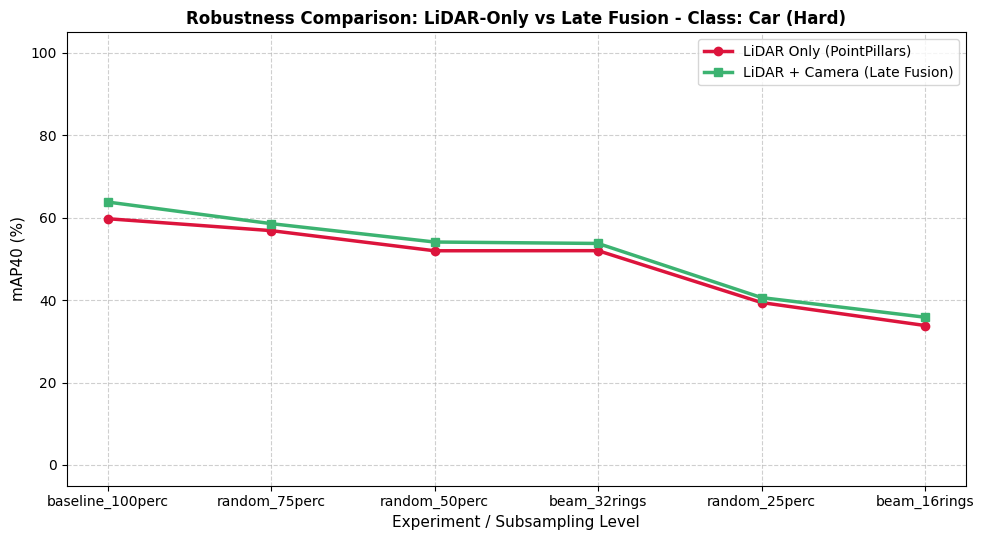

In [11]:
# Compute the gain matrix for the "Car" class under "Hard" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Car",
    difficulty="Hard",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Car" class under "Hard" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Car",
    difficulty="Hard",
    exclude_64beams=True,   # Remove 64 beams
    save_path=f"{learned_fusion_root}/overlay_car_hard.png",
)

### Pedestrian - Easy difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_easy.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_easy.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,53.82%,67.90%,+14.08%,+26.16%
1,random_75perc,55.25%,66.47%,+11.22%,+20.31%
2,random_50perc,54.77%,70.56%,+15.79%,+28.84%
3,beam_32rings,50.47%,52.55%,+2.08%,+4.13%
4,random_25perc,45.55%,48.27%,+2.72%,+5.98%
5,beam_16rings,31.75%,35.57%,+3.82%,+12.02%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_pedestrian_easy.png


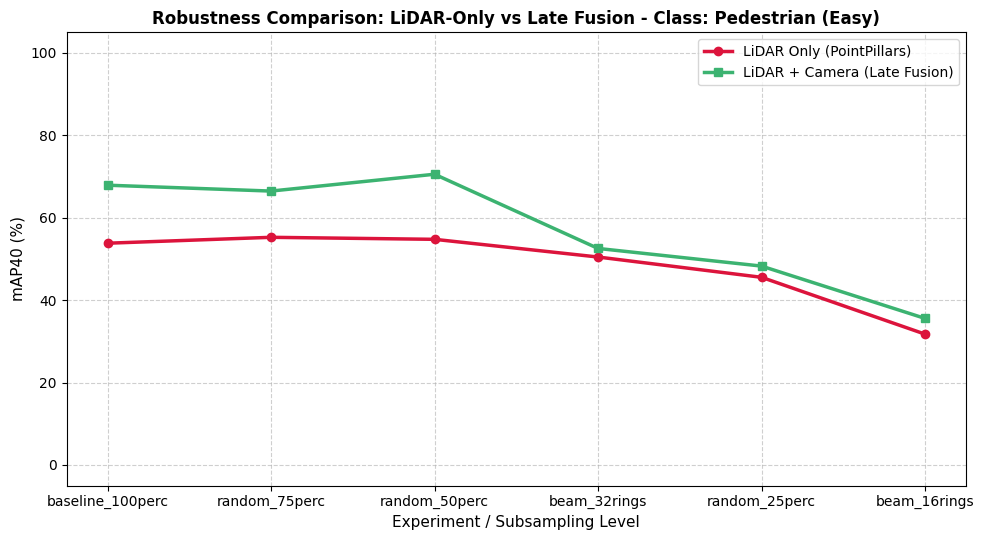

In [12]:
# Compute the gain matrix for the "Pedestrian" class under "Easy" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Pedestrian",
    difficulty="Easy",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Pedestrian" class under "Easy" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Pedestrian",
    difficulty="Easy",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_pedestrian_easy.png",
)

### Pedestrian - Moderate difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_moderate.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_moderate.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,49.63%,63.97%,+14.33%,+28.88%
1,random_75perc,49.38%,63.61%,+14.24%,+28.83%
2,random_50perc,49.56%,66.54%,+16.98%,+34.25%
3,beam_32rings,45.04%,50.53%,+5.49%,+12.18%
4,random_25perc,40.10%,42.81%,+2.71%,+6.75%
5,beam_16rings,26.97%,29.84%,+2.86%,+10.61%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_pedestrian_moderate.png


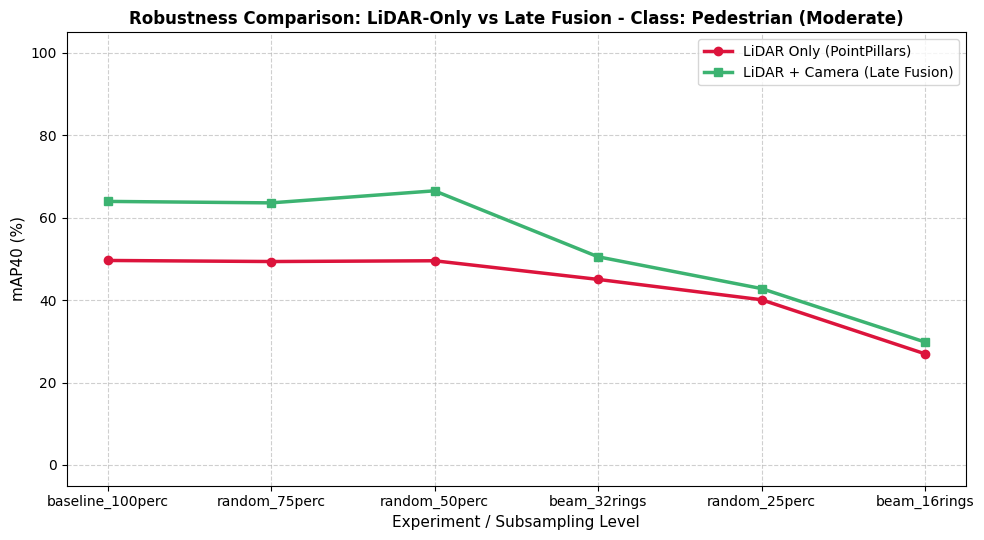

In [13]:
# Compute the gain matrix for the "Pedestrian" class under "Moderate" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Pedestrian",
    difficulty="Moderate",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Pedestrian" class under "Moderate" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Pedestrian",
    difficulty="Moderate",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_pedestrian_moderate.png",
)

### Pedestrian - Hard

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_hard.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_pedestrian_hard.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,44.13%,63.55%,+19.41%,+43.98%
1,random_75perc,44.93%,62.07%,+17.14%,+38.15%
2,random_50perc,44.68%,64.25%,+19.57%,+43.79%
3,beam_32rings,40.38%,50.52%,+10.14%,+25.11%
4,random_25perc,35.57%,40.35%,+4.78%,+13.45%
5,beam_16rings,24.00%,29.51%,+5.51%,+22.96%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_pedestrian_hard.png


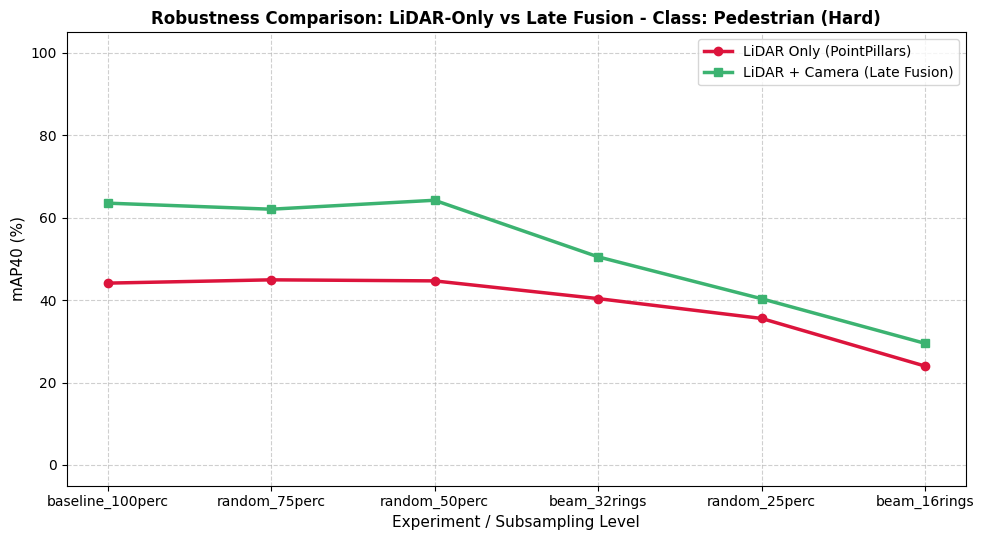

In [14]:
# Compute the gain matrix for the "Pedestrian" class under "Hard" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Pedestrian",
    difficulty="Hard",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Pedestrian" class under "Hard" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Pedestrian",
    difficulty="Hard",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_pedestrian_hard.png",
)

### Cyclist - Easy difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_easy.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_easy.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,48.11%,48.57%,+0.46%,+0.96%
1,random_75perc,50.24%,48.57%,-1.67%,-3.33%
2,random_50perc,46.91%,50.00%,+3.09%,+6.58%
3,beam_32rings,41.82%,33.33%,-8.49%,-20.30%
4,random_25perc,28.50%,20.00%,-8.50%,-29.83%
5,beam_16rings,18.90%,10.00%,-8.90%,-47.08%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_cyclist_easy.png


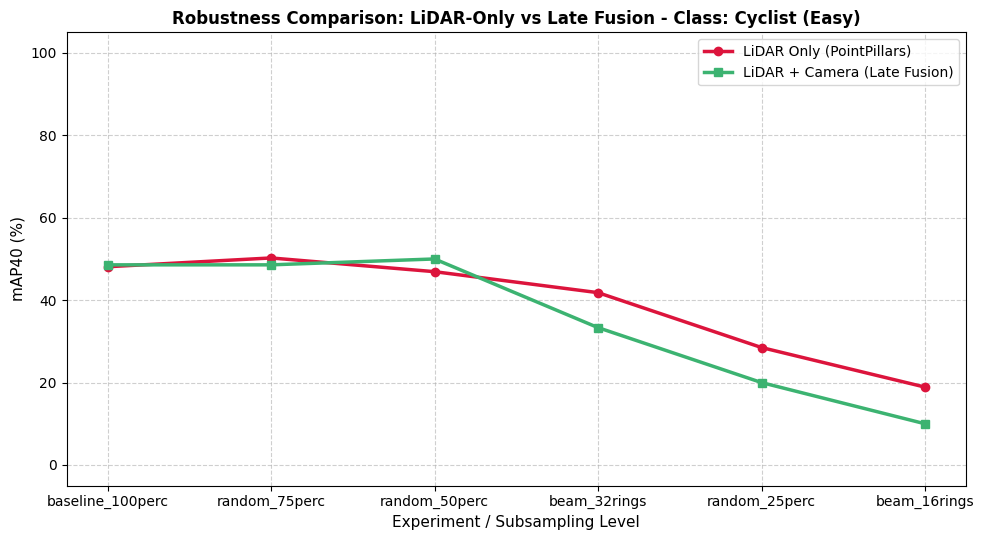

In [15]:
# Compute the gain matrix for the "Cyclist" class under "Easy" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Cyclist",
    difficulty="Easy",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Cyclist" class under "Easy" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Cyclist",
    difficulty="Easy",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_cyclist_easy.png",
)

### Cyclist - Moderate difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_moderate.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_moderate.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,43.70%,45.00%,+1.30%,+2.96%
1,random_75perc,40.88%,45.00%,+4.12%,+10.08%
2,random_50perc,35.78%,38.21%,+2.43%,+6.80%
3,beam_32rings,29.62%,38.00%,+8.38%,+28.30%
4,random_25perc,20.25%,20.00%,-0.25%,-1.22%
5,beam_16rings,13.45%,13.33%,-0.12%,-0.89%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_cyclist_moderate.png


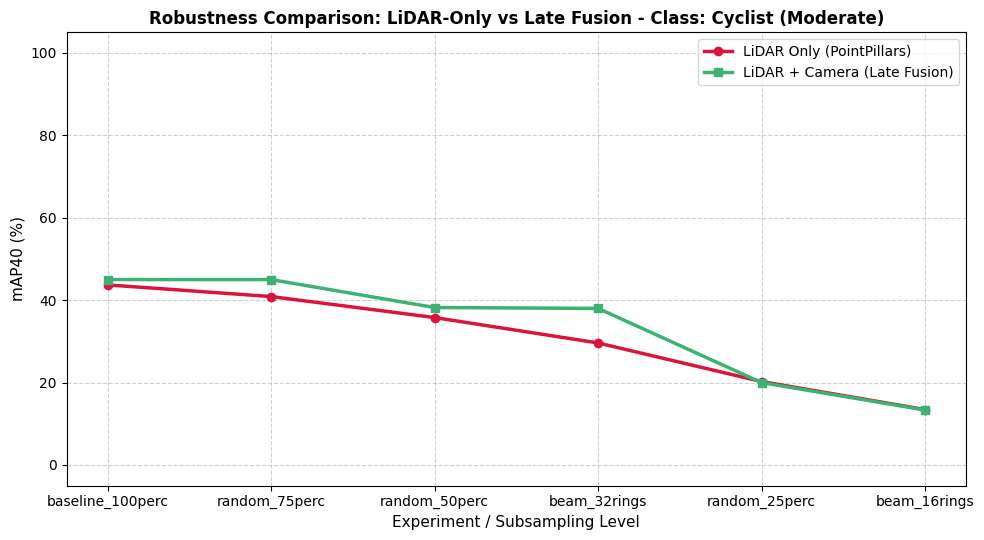

In [16]:
# Compute the gain matrix for the "Cyclist" class under "Moderate" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Cyclist",
    difficulty="Moderate",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Cyclist" class under "Moderate" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Cyclist",
    difficulty="Moderate",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_cyclist_moderate.png",
)

### Cyclist - Hard difficulty

 Gain Matrix saved to Drive: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_hard.csv and /content/drive/MyDrive/3D_Perception/experiments_fastcloc/reports/gain_matrix_cyclist_hard.md


,Experiment,LiDAR-Only (%),Late Fusion (%),Absolute Δ (% pts),Relative Δ (%)
0,baseline_100perc,42.59%,48.99%,+6.40%,+15.03%
1,random_75perc,40.34%,51.14%,+10.80%,+26.76%
2,random_50perc,35.57%,46.67%,+11.10%,+31.21%
3,beam_32rings,30.63%,47.50%,+16.87%,+55.09%
4,random_25perc,21.25%,32.50%,+11.25%,+52.94%
5,beam_16rings,14.93%,26.00%,+11.07%,+74.10%


 Overlay plot saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/overlay_cyclist_hard.png


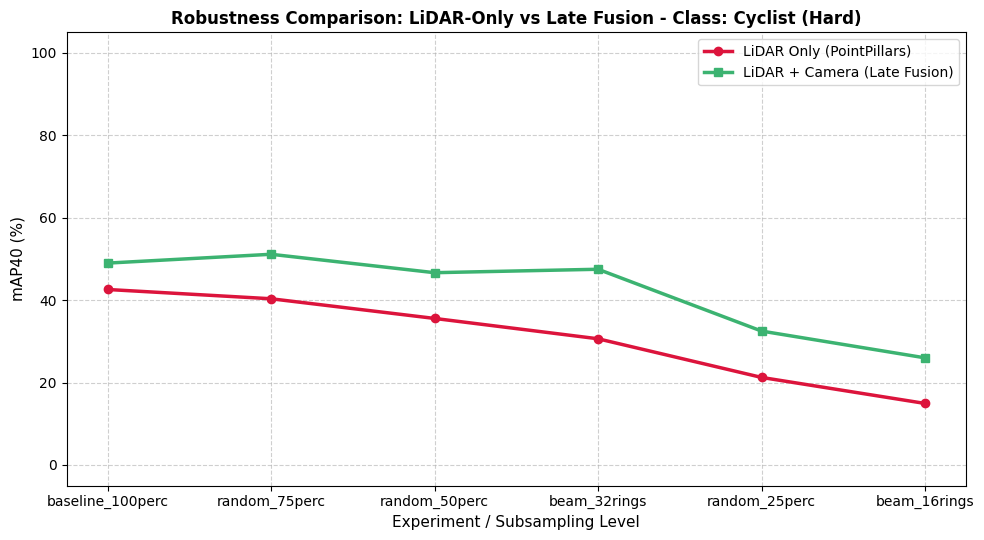

In [17]:
# Compute the gain matrix for the "Cyclist" class under "Hard" difficulty
df_gain_adaptive = comparer.compute_gain_matrix(
    target_class="Cyclist",
    difficulty="Hard",
    exclude_64beams=True,
    save_dir=f"{learned_fusion_root}/reports",
)

display(
    df_gain_adaptive.style.format({
        "LiDAR-Only (%)": "{:.2f}%",
        "Late Fusion (%)": "{:.2f}%",
        "Absolute Δ (% pts)": "{:+.2f}%",
        "Relative Δ (%)": "{:+.2f}%",
    })
)

# Compute the overlay plot for the "Cyclist" class under "Hard" difficulty
comparer.plot_fusion_vs_lidar_overlay(
    target_class="Cyclist",
    difficulty="Hard",
    exclude_64beams=True,   
    save_path=f"{learned_fusion_root}/overlay_cyclist_hard.png",
)

### Confusion matrix analysis - Baseline

Confusion Matrix saved to: /content/drive/MyDrive/3D_Perception/experiments/cm_lidar_baseline_100perc.png


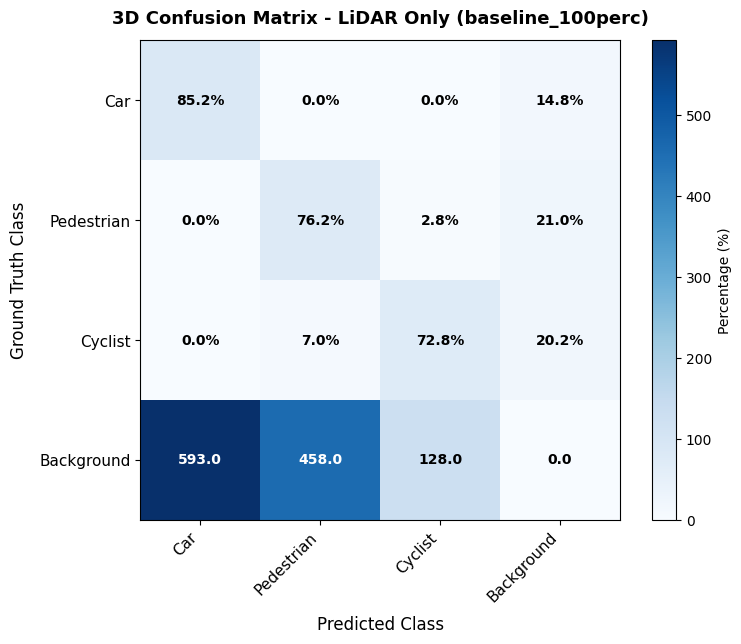

Confusion Matrix saved to: /content/drive/MyDrive/3D_Perception/experiments_fusion/cm_fusion_baseline_100perc.png


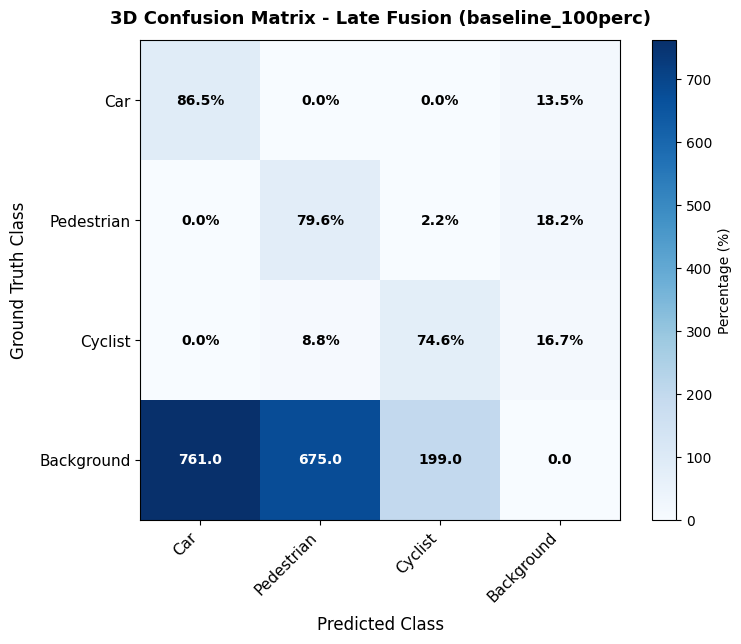

Confusion Matrix saved to: /content/drive/MyDrive/3D_Perception/experiments_fusion_adaptive/cm_fusion_baseline_100perc.png


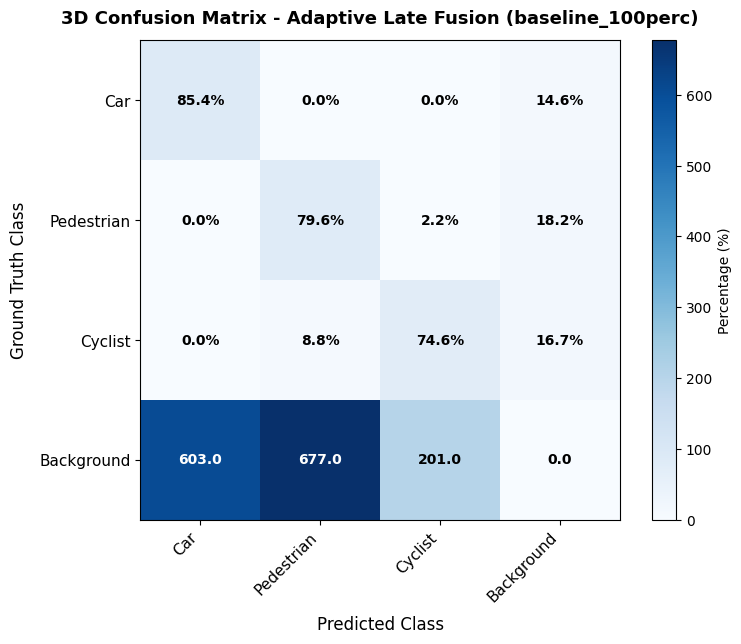

Confusion Matrix saved to: /content/drive/MyDrive/3D_Perception/experiments_fastcloc/cm_fusion_baseline_100perc.png


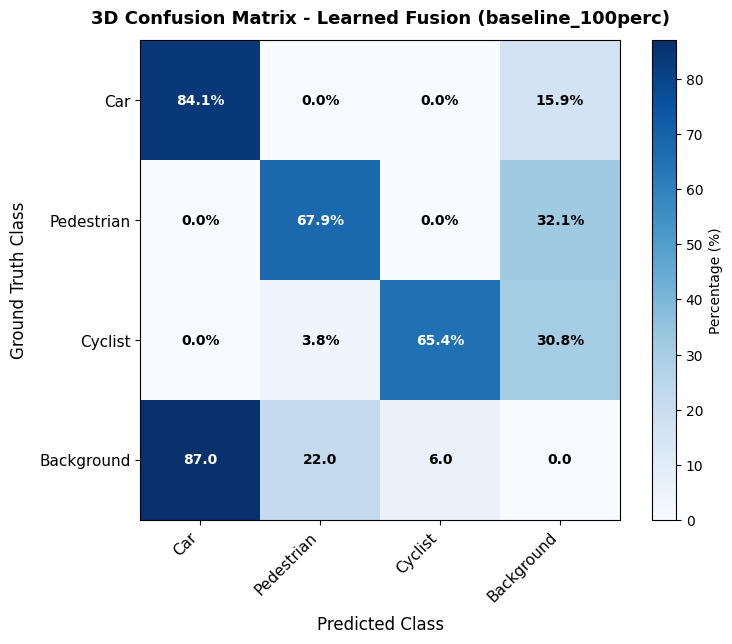

In [5]:
import sys
import os

sys.path.insert(0, "/content/3D_Perception")

from scripts.confusion_matrix import ConfusionMatrix3D

cm_calc = ConfusionMatrix3D(
    class_names=["Car", "Pedestrian", "Cyclist"],
    # iou_thresholds={"Car": 0.50, "Pedestrian": 0.25, "Cyclist": 0.25},
    conf_thresh=0.25
)

exp_target = "baseline_100perc"

# 1. LiDAR-Only matrix
matrix_lidar = cm_calc.compute_matrix(
    pred_dir=f"/content/drive/MyDrive/3D_Perception/experiments/{exp_target}/pred_labels",
    gt_dir=f"/content/drive/MyDrive/3D_Perception/experiments/{exp_target}/gt_labels"
)

cm_calc.plot_matrix(
    matrix_lidar,
    title=f"3D Confusion Matrix - LiDAR Only ({exp_target})",
    normalize=True,
    save_path=f"/content/drive/MyDrive/3D_Perception/experiments/cm_lidar_{exp_target}.png"
)

# 2. Late Fusion matrix
matrix_fusion = cm_calc.compute_matrix(
    pred_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fusion/fusion_{exp_target}/pred_labels",
    gt_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fusion/fusion_{exp_target}/gt_labels"
)

cm_calc.plot_matrix(
    matrix_fusion,  
    title=f"3D Confusion Matrix - Late Fusion ({exp_target})",
    normalize=True,
    save_path=f"/content/drive/MyDrive/3D_Perception/experiments_fusion/cm_fusion_{exp_target}.png"
)

# 3. Adaptive Late Fusion matrix
matrix_fusion_adaptive = cm_calc.compute_matrix(
    pred_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fusion_adaptive/fusion_{exp_target}/pred_labels",
    gt_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fusion_adaptive/fusion_{exp_target}/gt_labels"
)

cm_calc.plot_matrix(
    matrix_fusion_adaptive,
    title=f"3D Confusion Matrix - Adaptive Late Fusion ({exp_target})",
    normalize=True,
    save_path=f"/content/drive/MyDrive/3D_Perception/experiments_fusion_adaptive/cm_fusion_{exp_target}.png"
)

# 4. Learned Fusion matrix
matrix_fusion_learned = cm_calc.compute_matrix(
    pred_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fastcloc/{exp_target}/pred_labels",
    gt_dir=f"/content/drive/MyDrive/3D_Perception/experiments_fastcloc/{exp_target}/gt_labels" 
)

cm_calc.plot_matrix(
    matrix_fusion_learned,
    title=f"3D Confusion Matrix - Learned Fusion ({exp_target})",
    normalize=True,
    save_path=f"/content/drive/MyDrive/3D_Perception/experiments_fastcloc/cm_fusion_{exp_target}.png"
)

In [7]:
import glob

pred_files = glob.glob(f"{FASTCLOC_OUTPUT_BASE}/baseline_100perc/pred_labels/*.txt")
total_boxes = 0
high_conf_boxes = 0

for f in pred_files:
    with open(f, 'r') as file:
        for line in file:
            parts = line.strip().split()
            if parts:
                total_boxes += 1
                if float(parts[-1]) >= 0.30:
                    high_conf_boxes += 1

print(f"Totale box nei file predizioni (100 frame): {total_boxes} (Media: {total_boxes/100:.1f} box/frame)")
print(f"Box con score >= 0.30: {high_conf_boxes} (Media: {high_conf_boxes/100:.1f} box/frame)")

Totale box nei file predizioni (100 frame): 570 (Media: 5.7 box/frame)
Box con score >= 0.30: 570 (Media: 5.7 box/frame)
